# Pronóstico del ITAEE de Jalisco: estimación, combinaciones e intervalos

**Objetivo.** Pronosticar el ITAEE de Jalisco a 4 trimestres con cinco modelos y combinar sus pronósticos.

1. **Estimación:** suavización exponencial, regresión lineal y ARIMA (los dos últimos con EMEC mayoreo, EMEC menudeo y EMIM como exógenas, en versión *promedio* y *último mes* del trimestre).
2. **Combinaciones (6):** promedio simple, ponderado con **1/RMSE**, con **1/MSE** y con los **criterios de información** (BIC, AIC y AICc).
3. **Intervalos de predicción al 95%:** propios de cada modelo y a partir de los errores de validación.
4. **Dos escenarios para las exógenas:** *pronosticadas* (con suavización exponencial) y *observadas* (donde INEGI ya publicó el dato).

Todo corre desde `src/` (el mismo código que alimenta la página). La sección 7 escribe `site/data/resultados.json`.

> La sección 3 (validación cruzada) tarda unos 3 minutos.

In [1]:
import sys, re, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.tsa.statespace.sarimax import SARIMAX

RAIZ = Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))
import modelos as M, evaluacion as E, estimar as X, exportar
warnings.filterwarnings("ignore")
pd.set_option("display.width", 170); pd.set_option("display.float_format", "{:.3f}".format)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": .25})

COL = {k: v[2] for k, v in exportar.MODELOS_PAG.items()}
INDIV, COMB = M.MODELOS, E.ESQUEMAS

## 1. Los datos

La tabla trimestral trae el ITAEE (índice de volumen físico, 2018 = 100) y las exógenas en dos versiones: `_prom` (promedio de los 3 meses) y `_ultimo_mes`. Las exógenas empiezan en 2018 porque la EMIM real solo existe desde ese año.

Las filas **posteriores al último ITAEE** (si las hay) son las exógenas ya observadas que se usan en el escenario “observadas”.

In [2]:
full = M.cargar(RAIZ / "datos" / "series_macro_jalisco_trimestral.csv")
y = full["itaee_jalisco"].dropna()
d = full.loc[:y.index[-1]]            # lo que se usa para estimar
print("ITAEE:", y.index[0], "→", y.index[-1], f"({len(y)} trimestres)")
print("Exógenas observadas después del último ITAEE:", list(full.index[full.index > y.index[-1]]))
full.loc["2025Q3":]

ITAEE: 2003Q1 → 2026Q2 (94 trimestres)
Exógenas observadas después del último ITAEE: [Period('2026Q3', 'Q-DEC')]


,itaee_jalisco,emec_mayoreo_prom,emec_mayoreo_ultimo_mes,emec_menudeo_prom,emec_menudeo_ultimo_mes,emim_ventas_real_idx_prom,emim_ventas_real_idx_ultimo_mes
trimestre,,,,,,,
2025Q3,107.391,99.204,99.843,116.412,114.033,102.589,103.580
2025Q4,110.562,102.518,105.786,133.333,146.601,101.499,99.500
2026Q1,103.518,96.054,104.610,115.670,118.966,101.085,105.197
2026Q2,108.849,102.799,104.289,119.823,119.811,99.139,99.906
2026Q3,NaN,103.833,105.993,119.683,117.009,NaN,NaN


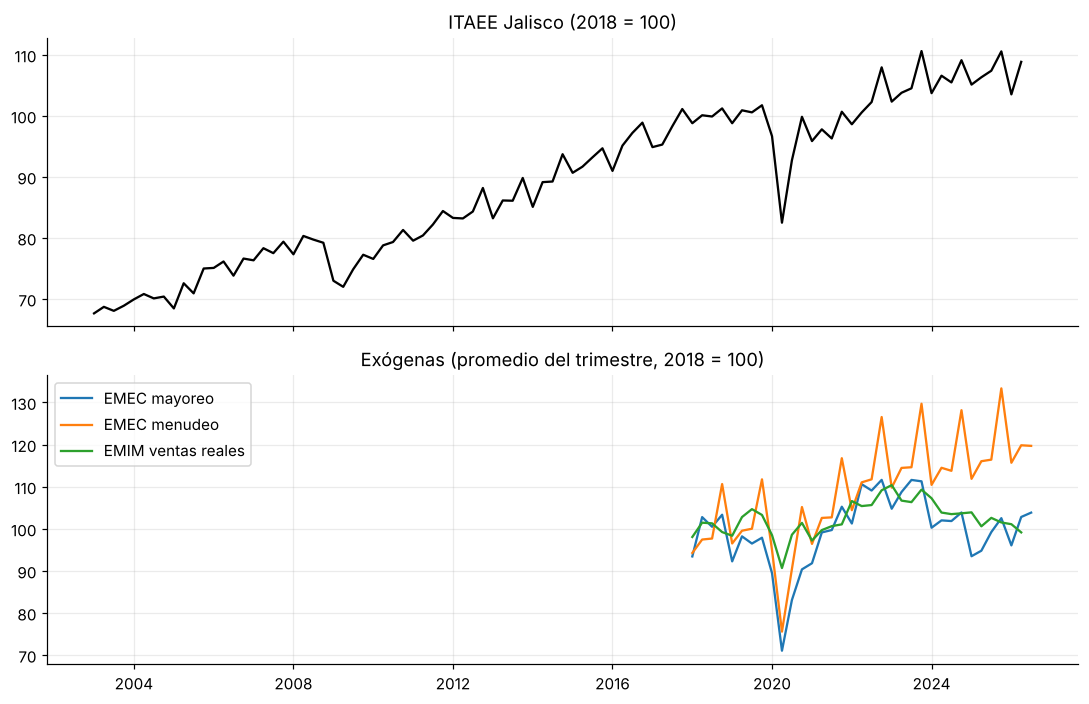

In [3]:
fig, ax = plt.subplots(2, 1, figsize=(10, 6.5), sharex=True)
ax[0].plot(y.index.to_timestamp(), y, color="k"); ax[0].set_title("ITAEE Jalisco (2018 = 100)")
z = full.loc["2018Q1":]
for c, n in [("emec_mayoreo_prom", "EMEC mayoreo"), ("emec_menudeo_prom", "EMEC menudeo"), ("emim_ventas_real_idx_prom", "EMIM ventas reales")]:
    ax[1].plot(z.index.to_timestamp(), z[c], label=n)
ax[1].set_title("Exógenas (promedio del trimestre, 2018 = 100)"); ax[1].legend(); plt.tight_layout(); plt.show()

## 2. Estimación: un modelo a la vez

Todos trabajan sobre **log(ITAEE)** y se regresan a nivel para reportar.

### 2.1 Suavización exponencial (ETS)
Error aditivo y estacionalidad aditiva de 4 trimestres. Se compara **sin tendencia** contra **tendencia amortiguada** y se elige por AIC. No usa exógenas.

In [4]:
ets = M.ets_fit(np.log(y))
print("Tendencia amortiguada:", ets.model.damped_trend, "| AIC:", round(ets.aic, 2))
print(ets.summary().tables[1])

Tendencia amortiguada: True | AIC: -384.91
                         coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------
smoothing_level        0.6612      0.121      5.453      0.000       0.424       0.899
smoothing_trend     6.612e-05        nan        nan        nan         nan         nan
smoothing_seasonal  3.388e-05        nan        nan        nan         nan         nan
damping_trend          0.9800      0.009    114.186      0.000       0.963       0.997
initial_level          4.2010        nan        nan        nan         nan         nan
initial_trend          0.0095      0.005      1.803      0.071      -0.001       0.020
initial_seasonal.0     0.0384        nan        nan        nan         nan         nan
initial_seasonal.1     0.0118        nan        nan        nan         nan         nan
initial_seasonal.2     0.0095        nan        nan        nan         nan         nan


### 2.2 Regresión lineal con exógenas
`log(ITAEE) ~ log(EMEC mayoreo) + log(EMEC menudeo) + log(EMIM) + dummy 2020T2`. Se estima con las dos versiones de las exógenas.

**Ojo:** los residuos de esta regresión están autocorrelacionados (Durbin-Watson bajo): los errores estándar son optimistas.

In [5]:
def ajustar_reg(cols):
    z = d.loc[M.INICIO_EXOG:].dropna(subset=["itaee_jalisco"] + cols)
    return sm.OLS(np.log(z["itaee_jalisco"]), sm.add_constant(M._x(z, cols))).fit()

reg = {v: ajustar_reg(M.EXOG[v]) for v in ["PROM", "ULT"]}
for v, t in [("PROM", "Promedio del trimestre"), ("ULT", "Último mes del trimestre")]:
    print(f"=== {t} ==="); print(reg[v].summary().tables[1]); print("R² =", round(reg[v].rsquared, 3), "| Durbin-Watson =", round(sm.stats.durbin_watson(reg[v].resid), 2), "\n")

=== Promedio del trimestre ===
                                coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------------
const                         2.5643      0.490      5.235      0.000       1.563       3.566
emec_mayoreo_prom            -0.0454      0.077     -0.589      0.561      -0.203       0.112
emec_menudeo_prom             0.4052      0.046      8.718      0.000       0.310       0.500
emim_ventas_real_idx_prom     0.0802      0.140      0.573      0.571      -0.206       0.366
covid                        -0.0718      0.026     -2.747      0.010      -0.125      -0.018
R² = 0.895 | Durbin-Watson = 0.74 

=== Último mes del trimestre ===
                                      coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------------------
const                               3.1571

### 2.3 ARIMA estacional con exógenas
Mismas variables, pero los errores siguen un proceso ARIMA estacional (`s = 4`). Se prueba una rejilla pequeña de órdenes y se elige el de menor **BIC**. En la tabla, `x1`, `x2`, `x3` son EMEC mayoreo, EMEC menudeo y EMIM, y `x4` es la dummy de 2020T2.

In [6]:
res = M.ajustar_y_pronosticar(d, obs=full)           # {escenario: {modelo: {f, lo, hi, ic, det}}}
arimax = {}
for v in ["PROM", "ULT"]:
    det = res["pron"][f"ARIMAX_{v}"]["det"]; p, dd, q, P, D = map(int, re.findall(r"\d+", det)[:5])
    z = d.loc[M.INICIO_EXOG:].dropna(subset=["itaee_jalisco"] + M.EXOG[v])
    arimax[v] = SARIMAX(np.log(z["itaee_jalisco"]).values, exog=M._x(z, M.EXOG[v]).values, order=(p, dd, q), seasonal_order=(P, D, 0, 4),
                        trend="c" if dd == 0 and D == 0 else "n").fit(disp=False, maxiter=200)
    print(f"{v}: {det}  BIC del modelo={arimax[v].bic:.1f}")
print(arimax["PROM"].summary().tables[1])

PROM: order=(1,0,0) seasonal=(0,0,0,4)  BIC del modelo=-172.9
ULT: order=(0,1,1) seasonal=(0,0,0,4)  BIC del modelo=-153.7
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
intercept      0.6261      0.537      1.165      0.244      -0.427       1.679
x1             0.0476      0.088      0.542      0.588      -0.125       0.220
x2             0.3130      0.058      5.351      0.000       0.198       0.428
x3             0.1173      0.151      0.776      0.438      -0.179       0.414
x4            -0.0557      0.018     -3.173      0.002      -0.090      -0.021
ar.L1          0.7391      0.184      4.013      0.000       0.378       1.100
sigma2         0.0002    4.8e-05      3.566      0.000    7.71e-05       0.000


### 2.4 Ajuste dentro de la muestra
Ajuste ≠ capacidad de pronosticar (eso se mide en la sección 3), pero sirve para ver si algún modelo se equivoca de forma sistemática.

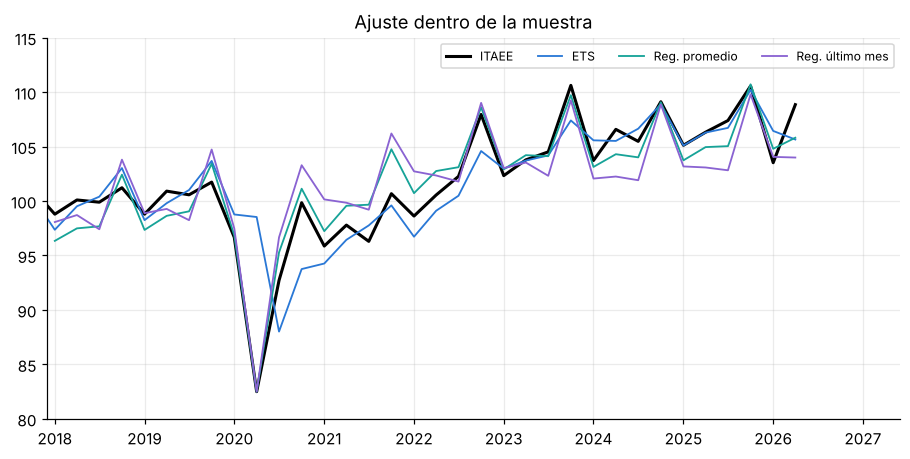

In [7]:
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(y.index.to_timestamp(), y, color="k", lw=2, label="ITAEE")
f = np.exp(ets.fittedvalues); ax.plot(f.index.to_timestamp(), f, color=COL["ETS"], lw=1.2, label="ETS")
for v, nom in [("PROM", "Reg. promedio"), ("ULT", "Reg. último mes")]:
    f = np.exp(reg[v].fittedvalues); ax.plot(f.index.to_timestamp(), f, color=COL["REG_" + v], lw=1.2, label=nom)
ax.set_xlim(pd.Timestamp("2017-12-01"), None); ax.set_ylim(80, 115); ax.legend(ncol=4, fontsize=8); ax.set_title("Ajuste dentro de la muestra"); plt.show()

### 2.5 Pronóstico a 4 trimestres de cada modelo, en los dos escenarios

* **Exógenas pronosticadas:** primero se pronostican EMEC y EMIM con suavización exponencial y esos valores entran a la regresión y al ARIMA.
* **Exógenas observadas:** donde INEGI ya publicó el trimestre completo se usa el valor real (hoy, la EMEC de 2026T3); el resto se completa con el pronóstico. La EMIM de 2026T3 todavía no tiene los tres meses.

ETS no usa exógenas, así que no cambia.

In [8]:
idx = pd.period_range(y.index[-1] + 1, periods=M.H, freq="Q")
ex = X.exog_final(d, full)
print("Exógenas (promedio del trimestre) que entran al pronóstico final:")
display(pd.concat({"pronosticadas": ex["pron"], "observadas": ex["obs"]}, axis=1).round(2))
print("¿El valor es observado?"); display(ex["observado"])

ind = pd.concat({e: pd.DataFrame({m: res[e][m]["f"] for m in INDIV}, index=idx) for e in ["pron", "obs"]}, axis=1)
print("Pronósticos individuales"); ind

Exógenas (promedio del trimestre) que entran al pronóstico final:


pronosticadas                                                    observadas                                            
       emec_mayoreo_prom emec_menudeo_prom emim_ventas_real_idx_prom emec_mayoreo_prom emec_menudeo_prom emim_ventas_real_idx_prom
2026Q3           104.880           120.750                   100.890           103.830           119.680                   100.890
2026Q4           108.000           136.180                   101.480           108.000           136.180                   101.480
2027Q1           100.420           118.090                   100.590           100.420           118.090                   100.590
2027Q2           102.800           118.810                    99.350           102.800           118.810                    99.350

¿El valor es observado?


,emec_mayoreo_prom,emec_menudeo_prom,emim_ventas_real_idx_prom
2026Q3,True,True,False
2026Q4,False,False,False
2027Q1,False,False,False
2027Q2,False,False,False


Pronósticos individuales


pron                                             obs                                        
           ETS REG_PROM REG_ULT ARIMAX_PROM ARIMAX_ULT     ETS REG_PROM REG_ULT ARIMAX_PROM ARIMAX_ULT
2026Q3 108.156  106.196 103.463     108.527    106.933 108.156  105.862 103.309     108.174    107.296
2026Q4 111.219  111.402 110.305     112.228    111.527 111.219  111.402 110.305     112.228    111.527
2027Q1 107.173  105.424 104.486     106.361    107.233 107.173  105.424 104.486     106.361    107.233
2027Q2 108.342  105.467 103.952     106.167    107.436 108.342  105.467 103.952     106.167    107.436

## 3. Validación cruzada: ¿cuál pronostica mejor?

Se hace una **ventana expansiva**: se estima con datos hasta un trimestre *T* (desde 2022T4), se pronostica *T+1…T+4* y se compara con lo que realmente pasó. Cada modelo se evalúa solo con pronósticos *que nunca vio*. Se hace en **los dos escenarios**.

Medidas (como en la presentación): ME, MAE, RMSE, MPE, MAPE, MASE, ACF1 y **U de Theil** (menor a 1 = mejor que repetir el último valor). Errores = real − pronóstico.

> En el escenario “observadas”, las exógenas del periodo pronosticado son las observadas: es un pronóstico **condicional**, no uno que se pudiera haber hecho en tiempo real. Sirve para ver cuánto del error viene de no conocer las exógenas.

### Combinaciones

| Esquema | Peso de cada modelo |
|---|---|
| Simple | 1/5 |
| 1/RMSE | $w_i = \dfrac{1/\mathrm{RMSE}_i}{\sum_j 1/\mathrm{RMSE}_j}$, por horizonte |
| 1/MSE | $w_i = \dfrac{1/\mathrm{MSE}_i}{\sum_j 1/\mathrm{MSE}_j}$ (inverso de la varianza del error), por horizonte |
| BIC, AIC, AICc | $a_i = e^{(IC^* - IC_i)/2}$, $w_i = a_i / \sum_j a_j$ |

Los criterios se calculan con los últimos 20 residuos de cada modelo (ventana común) para que sean comparables; el AICc corrige por muestra chica.
Al evaluar las combinaciones *dentro* de la validación, los pesos de cada origen usan solo los errores que ya se conocían en ese momento.

In [9]:
R = X.correr(full)
Rp, Ro = R["esc"]["pron"], R["esc"]["obs"]
print("Pronósticos evaluados por escenario:", int((Rp["cv"].modelo == "ETS").sum()) , "por modelo |", "orígenes:", Rp["cv"]["origen"].nunique())

1/4 Validación cruzada (ventana expansiva, dos escenarios)…


2/4 Pronóstico final…


3/4 Medidas, combinaciones e intervalos…


Pronósticos evaluados por escenario: 50 por modelo | orígenes: 14


In [10]:
def tabla_h(esc, h):
    t = R["esc"][esc]["medidas"].query("h == @h").set_index("modelo").loc[INDIV + COMB, ["n", "ME", "MAE", "RMSE", "MAPE", "MASE", "ACF1", "Theil_U"]]
    return t.style.format(precision=3).highlight_min(subset=["RMSE"], color="#cdebd4")

print("Exógenas PRONOSTICADAS · horizonte 1 trimestre"); display(tabla_h("pron", 1))
print("Exógenas PRONOSTICADAS · horizonte 4 trimestres"); display(tabla_h("pron", 4))

Exógenas PRONOSTICADAS · horizonte 1 trimestre


,n,ME,MAE,RMSE,MAPE,MASE,ACF1,Theil_U
modelo,,,,,,,,
ETS,14,0.101,1.321,1.783,1.242,0.443,-0.611,0.428
REG_PROM,14,1.850,1.994,2.476,1.858,0.669,-0.401,0.603
REG_ULT,14,3.178,3.246,3.716,3.036,1.089,-0.179,0.904
ARIMAX_PROM,14,0.531,1.596,1.975,1.498,0.535,-0.595,0.481
ARIMAX_ULT,14,0.787,1.988,2.453,1.866,0.666,-0.399,0.597
COMB_SIMPLE,14,1.289,1.766,2.190,1.652,0.592,-0.548,0.535
COMB_RMSE,14,1.096,1.652,2.102,1.547,0.554,-0.558,0.513
COMB_VARIANZA,14,0.958,1.634,2.060,1.531,0.548,-0.557,0.502
COMB_BIC,14,0.537,1.597,1.973,1.499,0.536,-0.593,0.481


Exógenas PRONOSTICADAS · horizonte 4 trimestres


,n,ME,MAE,RMSE,MAPE,MASE,ACF1,Theil_U
modelo,,,,,,,,
ETS,11,0.472,1.216,1.490,1.131,0.408,-0.280,0.811
REG_PROM,11,2.739,2.739,3.098,2.540,0.919,-0.518,1.685
REG_ULT,11,4.024,4.024,4.363,3.743,1.349,-0.282,2.380
ARIMAX_PROM,11,1.387,1.660,2.027,1.542,0.557,-0.402,1.107
ARIMAX_ULT,11,2.390,2.715,3.050,2.532,0.910,-0.242,1.671
COMB_SIMPLE,11,2.203,2.348,2.631,2.182,0.787,-0.456,1.436
COMB_RMSE,11,2.015,2.218,2.475,2.063,0.744,-0.420,1.352
COMB_VARIANZA,11,1.840,2.098,2.355,1.952,0.703,-0.344,1.287
COMB_BIC,11,1.387,1.660,2.026,1.543,0.557,-0.396,1.107


In [11]:
print("Exógenas OBSERVADAS · horizonte 1 trimestre"); display(tabla_h("obs", 1))
print("Exógenas OBSERVADAS · horizonte 4 trimestres"); display(tabla_h("obs", 4))

Exógenas OBSERVADAS · horizonte 1 trimestre


,n,ME,MAE,RMSE,MAPE,MASE,ACF1,Theil_U
modelo,,,,,,,,
ETS,14,0.101,1.321,1.783,1.242,0.443,-0.611,0.428
REG_PROM,14,1.823,2.092,2.420,1.954,0.701,0.002,0.588
REG_ULT,14,3.270,3.329,3.736,3.115,1.116,0.050,0.906
ARIMAX_PROM,14,0.513,1.261,1.666,1.185,0.423,-0.542,0.405
ARIMAX_ULT,14,0.796,1.834,2.364,1.714,0.615,-0.159,0.575
COMB_SIMPLE,14,1.301,1.703,2.113,1.592,0.571,-0.320,0.515
COMB_RMSE,14,1.062,1.533,1.980,1.433,0.514,-0.363,0.483
COMB_VARIANZA,14,0.906,1.447,1.914,1.353,0.485,-0.387,0.466
COMB_BIC,14,0.519,1.271,1.668,1.193,0.426,-0.529,0.406


Exógenas OBSERVADAS · horizonte 4 trimestres


,n,ME,MAE,RMSE,MAPE,MASE,ACF1,Theil_U
modelo,,,,,,,,
ETS,11,0.472,1.216,1.490,1.131,0.408,-0.280,0.811
REG_PROM,11,3.177,3.230,3.455,3.007,1.083,-0.094,1.886
REG_ULT,11,4.332,4.332,4.686,4.036,1.452,0.006,2.565
ARIMAX_PROM,11,1.605,1.884,2.084,1.759,0.632,-0.241,1.144
ARIMAX_ULT,11,2.489,3.053,3.522,2.860,1.024,0.366,1.938
COMB_SIMPLE,11,2.415,2.667,2.851,2.488,0.894,-0.012,1.563
COMB_RMSE,11,2.233,2.526,2.728,2.358,0.847,0.081,1.497
COMB_VARIANZA,11,2.072,2.404,2.646,2.245,0.806,0.164,1.452
COMB_BIC,11,1.587,1.892,2.083,1.766,0.634,-0.204,1.144


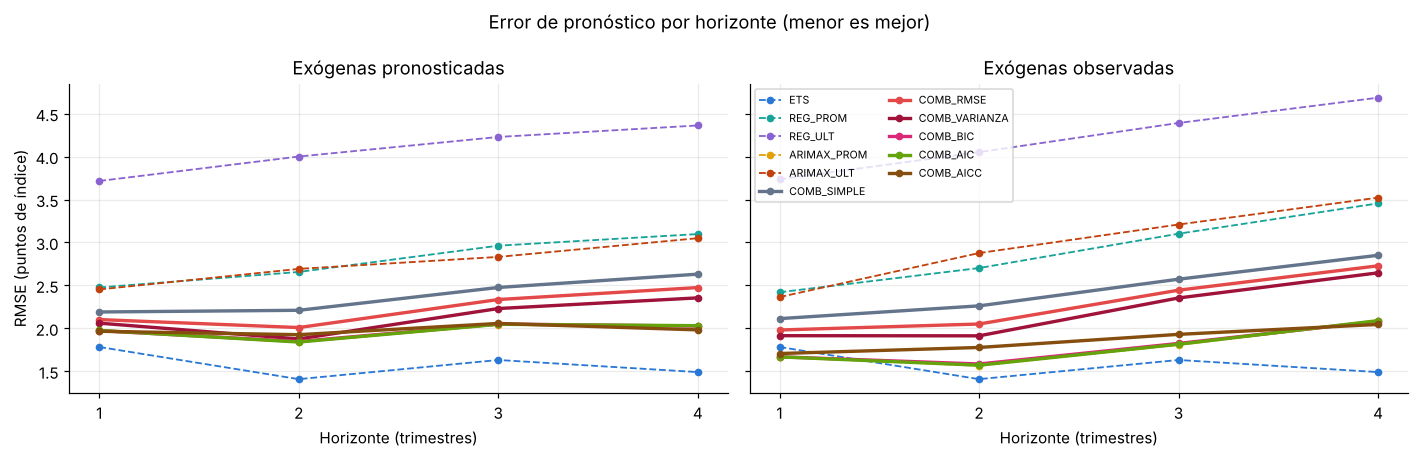

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
for a, (e, t) in zip(ax, [("pron", "Exógenas pronosticadas"), ("obs", "Exógenas observadas")]):
    rm = R["esc"][e]["medidas"].pivot(index="h", columns="modelo", values="RMSE")[INDIV + COMB]
    for m in INDIV + COMB: a.plot(rm.index, rm[m], "o-" if m in COMB else "o--", color=COL[m], lw=2.2 if m in COMB else 1.2, ms=4, label=m)
    a.set_xticks([1, 2, 3, 4]); a.set_xlabel("Horizonte (trimestres)"); a.set_title(t)
ax[0].set_ylabel("RMSE (puntos de índice)"); ax[1].legend(ncol=2, fontsize=7); plt.suptitle("Error de pronóstico por horizonte (menor es mejor)"); plt.tight_layout(); plt.show()

### 3.1 Los pesos
Los pesos por error (1/RMSE y 1/MSE) salen de la validación cruzada del escenario elegido y cambian por horizonte. Los de BIC, AIC y AICc salen del ajuste de cada modelo y son los mismos en los dos escenarios.

In [13]:
def pesos_h(esc, h):
    P = R["esc"][esc]["pesos"]
    return pd.DataFrame({q.replace("COMB_", ""): P[q][h] for q in COMB}).loc[INDIV]

print("Criterios de información (ventana común de 20 residuos)"); display(R["ic"])
print("Pesos · escenario pronosticadas · horizonte 1"); display(pesos_h("pron", 1).style.format("{:.1%}").background_gradient(cmap="Blues", vmin=0, vmax=1))
print("Pesos · escenario pronosticadas · horizonte 4"); display(pesos_h("pron", 4).style.format("{:.1%}").background_gradient(cmap="Blues", vmin=0, vmax=1))

Criterios de información (ventana común de 20 residuos)


,bic,aic,aicc
ETS,-134.355,-144.312,-119.868
REG_PROM,-142.996,-148.970,-142.509
REG_ULT,-125.907,-131.882,-125.420
ARIMAX_PROM,-152.433,-159.403,-150.070
ARIMAX_ULT,-145.033,-151.008,-144.546


Pesos · escenario pronosticadas · horizonte 1


,SIMPLE,RMSE,VARIANZA,BIC,AIC,AICC
ETS,20.0%,26.1%,32.3%,0.0%,0.1%,0.0%
REG_PROM,20.0%,18.8%,16.8%,0.9%,0.5%,2.1%
REG_ULT,20.0%,12.5%,7.4%,0.0%,0.0%,0.0%
ARIMAX_PROM,20.0%,23.6%,26.3%,96.7%,97.9%,92.1%
ARIMAX_ULT,20.0%,19.0%,17.1%,2.4%,1.5%,5.8%


Pesos · escenario pronosticadas · horizonte 4


,SIMPLE,RMSE,VARIANZA,BIC,AIC,AICC
ETS,20.0%,32.8%,47.0%,0.0%,0.1%,0.0%
REG_PROM,20.0%,15.8%,10.9%,0.9%,0.5%,2.1%
REG_ULT,20.0%,11.2%,5.5%,0.0%,0.0%,0.0%
ARIMAX_PROM,20.0%,24.1%,25.4%,96.7%,97.9%,92.1%
ARIMAX_ULT,20.0%,16.0%,11.2%,2.4%,1.5%,5.8%


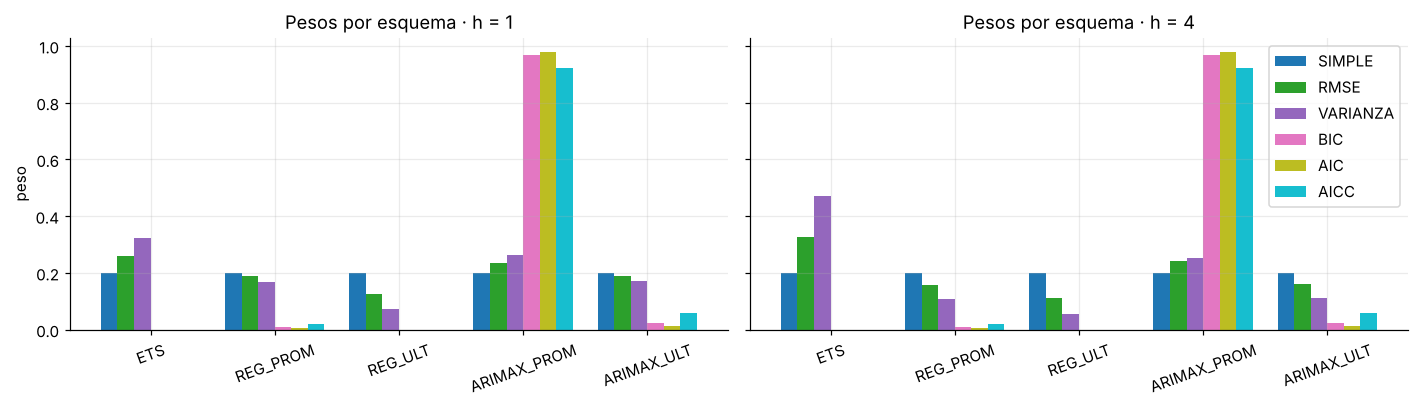

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
for a, h in zip(ax, [1, 4]): pesos_h("pron", h).plot.bar(ax=a, width=.8, colormap="tab10", legend=(h == 4)); a.set_title(f"Pesos por esquema · h = {h}"); a.tick_params(axis="x", rotation=20)
ax[0].set_ylabel("peso"); plt.tight_layout(); plt.show()

## 4. Intervalos de predicción al 95%

Dos tipos, para todos los modelos:

* **Del modelo:** ETS, regresión y ARIMAX dan su propio intervalo (en logaritmos, luego pasado a nivel). No incluye la incertidumbre de las exógenas que se pronostican. Las **combinaciones no tienen intervalo propio**.
* **De la validación:** centro ± *t*·RMSE, donde el RMSE es el de la validación cruzada de ese modelo y horizonte y *t* es de Student con *n − 1* g.l. (son pocos errores: 11 a 14).

Además se revisa la **cobertura**: qué proporción de lo observado cayó dentro del intervalo propio del modelo en la validación. Lo esperado es cerca de 95%.

In [15]:
def intervalos(esc, tipo):
    r = R["esc"][esc]; lo, hi = (r["lo_modelo"], r["hi_modelo"]) if tipo == "modelo" else (r["lo_val"], r["hi_val"])
    cols = INDIV if tipo == "modelo" else INDIV + COMB
    return pd.DataFrame({m: [f"{lo.loc[t, m]:.1f} – {hi.loc[t, m]:.1f}" for t in idx] for m in cols}, index=[str(t) for t in idx]).T

print("Intervalos propios del modelo (exógenas pronosticadas)"); display(intervalos("pron", "modelo"))
print("Intervalos de la validación (exógenas pronosticadas)"); display(intervalos("pron", "val"))
print("Cobertura del intervalo propio en la validación"); display(Rp["cobertura"].style.format("{:.0%}"))

Intervalos propios del modelo (exógenas pronosticadas)


,2026Q3,2026Q4,2027Q1,2027Q2
ETS,102.4 – 114.2,104.2 – 118.7,99.5 – 115.5,99.7 – 117.7
REG_PROM,101.8 – 110.8,106.5 – 116.6,101.1 – 109.9,101.0 – 110.1
REG_ULT,97.4 – 109.8,103.4 – 117.7,98.4 – 110.9,97.9 – 110.4
ARIMAX_PROM,105.8 – 111.3,108.7 – 115.9,102.7 – 110.1,102.4 – 110.1
ARIMAX_ULT,103.4 – 110.6,107.2 – 116.0,102.5 – 112.2,102.2 – 112.9


Intervalos de la validación (exógenas pronosticadas)


,2026Q3,2026Q4,2027Q1,2027Q2
ETS,104.3 – 112.0,108.2 – 114.3,103.6 – 110.8,105.0 – 111.7
REG_PROM,100.8 – 111.5,105.6 – 117.2,98.9 – 111.9,98.6 – 112.4
REG_ULT,95.4 – 111.5,101.6 – 119.0,95.2 – 113.8,94.2 – 113.7
ARIMAX_PROM,104.3 – 112.8,108.2 – 116.2,101.9 – 110.9,101.7 – 110.7
ARIMAX_ULT,101.6 – 112.2,105.7 – 117.4,101.0 – 113.5,100.6 – 114.2
COMB_SIMPLE,101.9 – 111.4,106.5 – 116.2,100.7 – 111.6,100.4 – 112.1
COMB_RMSE,102.5 – 111.6,107.1 – 115.8,101.2 – 111.5,101.2 – 112.2
COMB_VARIANZA,102.9 – 111.8,107.4 – 115.6,101.7 – 111.5,101.9 – 112.4
COMB_BIC,104.2 – 112.7,108.2 – 116.2,101.9 – 110.9,101.7 – 110.7
COMB_AIC,104.2 – 112.8,108.2 – 116.2,101.9 – 110.9,101.7 – 110.7


Cobertura del intervalo propio en la validación


h,1,2,3,4
modelo,,,,
ARIMAX_PROM,86%,92%,75%,91%
ARIMAX_ULT,86%,77%,92%,82%
ETS,100%,100%,100%,100%
REG_PROM,93%,92%,92%,82%
REG_ULT,93%,92%,83%,91%


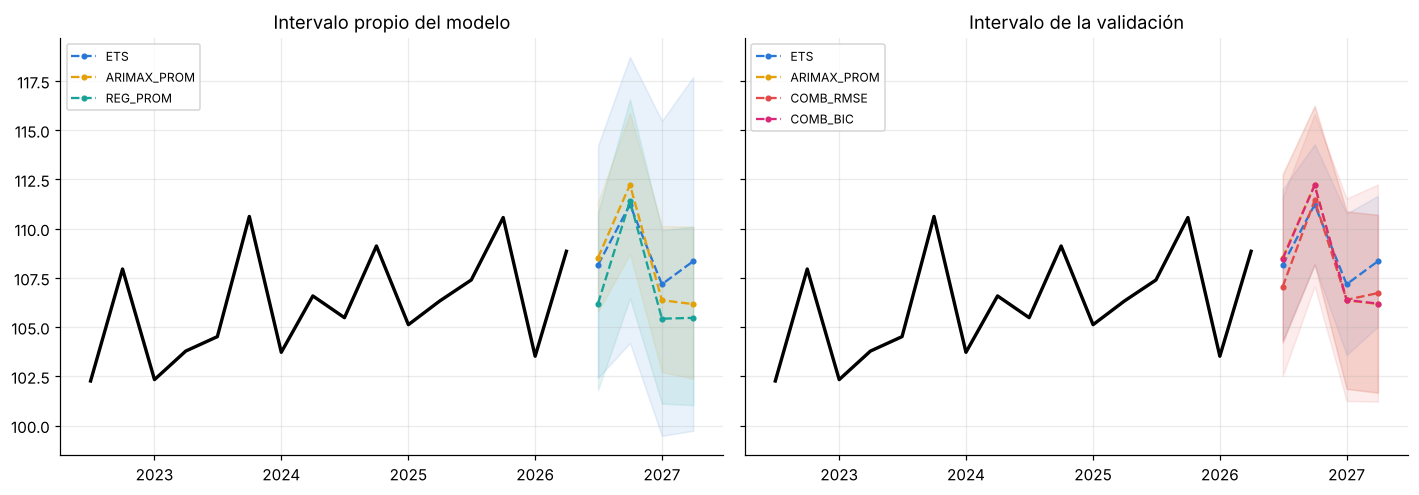

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.6), sharey=True); h = y.iloc[-16:]
for a, (tipo, t) in zip(ax, [("modelo", "Intervalo propio del modelo"), ("val", "Intervalo de la validación")]):
    lo, hi = (Rp["lo_modelo"], Rp["hi_modelo"]) if tipo == "modelo" else (Rp["lo_val"], Rp["hi_val"])
    a.plot(h.index.to_timestamp(), h, "k", lw=2.2)
    for m in (["ETS", "ARIMAX_PROM", "REG_PROM"] if tipo == "modelo" else ["ETS", "ARIMAX_PROM", "COMB_RMSE", "COMB_BIC"]):
        a.plot(idx.to_timestamp(), Rp["pron"][m], "o--", color=COL[m], ms=3, label=m)
        a.fill_between(idx.to_timestamp(), lo[m], hi[m], color=COL[m], alpha=.10)
    a.set_title(t); a.legend(fontsize=8)
plt.tight_layout(); plt.show()

## 5. ¿Cambia algo con las exógenas observadas?

Comparación del RMSE de validación con exógenas pronosticadas contra observadas (negativo = mejora al usar las observadas).

In [17]:
cmp = {}
for h in [1, 2, 3, 4]:
    a = Rp["medidas"].query("h == @h").set_index("modelo")["RMSE"]; b = Ro["medidas"].query("h == @h").set_index("modelo")["RMSE"]
    cmp[f"h={h} pron."] = a; cmp[f"h={h} obs."] = b; cmp[f"h={h} Δ"] = b - a
display(pd.DataFrame(cmp).loc[INDIV + COMB].style.format(precision=2).background_gradient(cmap="RdYlGn_r", subset=[c for c in pd.DataFrame(cmp).columns if "Δ" in c], vmin=-.6, vmax=.6))

,h=1 pron.,h=1 obs.,h=1 Δ,h=2 pron.,h=2 obs.,h=2 Δ,h=3 pron.,h=3 obs.,h=3 Δ,h=4 pron.,h=4 obs.,h=4 Δ
modelo,,,,,,,,,,,,
ETS,1.78,1.78,0.00,1.41,1.41,0.00,1.63,1.63,0.00,1.49,1.49,0.00
REG_PROM,2.48,2.42,-0.06,2.66,2.70,0.05,2.96,3.10,0.14,3.10,3.46,0.36
REG_ULT,3.72,3.74,0.02,4.00,4.05,0.05,4.23,4.39,0.16,4.36,4.69,0.32
ARIMAX_PROM,1.98,1.67,-0.31,1.84,1.56,-0.27,2.04,1.81,-0.24,2.03,2.08,0.06
ARIMAX_ULT,2.45,2.36,-0.09,2.69,2.88,0.18,2.83,3.21,0.38,3.05,3.52,0.47
COMB_SIMPLE,2.19,2.11,-0.08,2.21,2.26,0.05,2.48,2.57,0.10,2.63,2.85,0.22
COMB_RMSE,2.10,1.98,-0.12,2.01,2.05,0.04,2.34,2.44,0.11,2.47,2.73,0.25
COMB_VARIANZA,2.06,1.91,-0.15,1.88,1.91,0.04,2.23,2.35,0.12,2.35,2.65,0.29
COMB_BIC,1.97,1.67,-0.30,1.85,1.58,-0.26,2.05,1.82,-0.23,2.03,2.08,0.06


## 6. Pronóstico final combinado

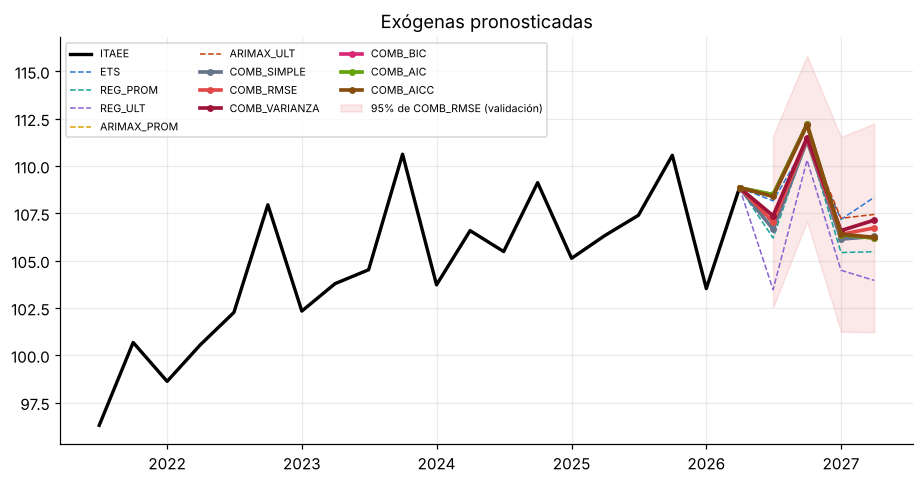

,2026Q3,2026Q4,2027Q1,2027Q2
ETS,108.16,111.22,107.17,108.34
REG_PROM,106.20,111.40,105.42,105.47
REG_ULT,103.46,110.30,104.49,103.95
ARIMAX_PROM,108.53,112.23,106.36,106.17
ARIMAX_ULT,106.93,111.53,107.23,107.44
COMB_SIMPLE,106.65,111.34,106.14,106.27
COMB_RMSE,107.05,111.44,106.38,106.73
COMB_VARIANZA,107.37,111.49,106.58,107.13
COMB_BIC,108.47,112.20,106.37,106.19
COMB_AIC,108.49,112.21,106.37,106.18


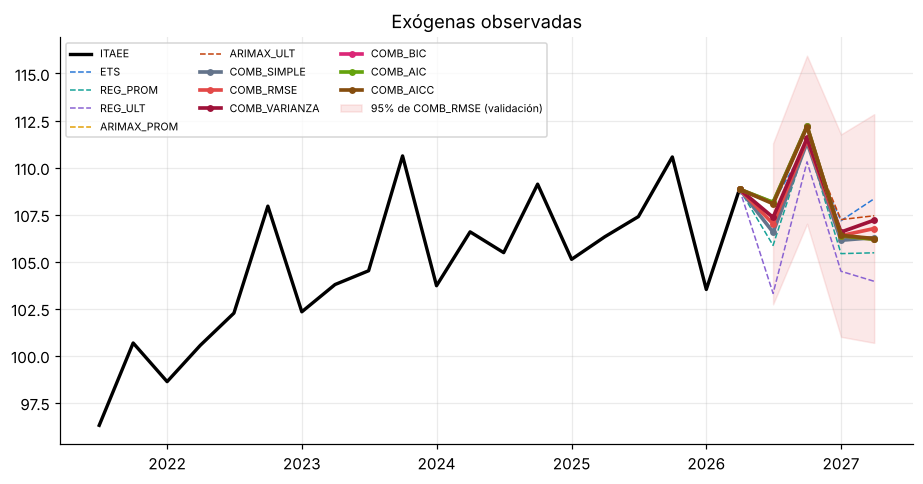

,2026Q3,2026Q4,2027Q1,2027Q2
ETS,108.16,111.22,107.17,108.34
REG_PROM,105.86,111.40,105.42,105.47
REG_ULT,103.31,110.30,104.49,103.95
ARIMAX_PROM,108.17,112.23,106.36,106.17
ARIMAX_ULT,107.30,111.53,107.23,107.44
COMB_SIMPLE,106.56,111.34,106.14,106.27
COMB_RMSE,107.01,111.48,106.38,106.76
COMB_VARIANZA,107.35,111.56,106.57,107.20
COMB_BIC,108.13,112.20,106.37,106.19
COMB_AIC,108.15,112.21,106.37,106.18


In [18]:
def final(esc, titulo):
    r = R["esc"][esc]; fig, ax = plt.subplots(figsize=(10, 4.8)); h = y.iloc[-20:]
    ax.plot(h.index.to_timestamp(), h, color="k", lw=2.2, label="ITAEE")
    for m in INDIV + COMB:
        s = pd.concat([y.iloc[[-1]], r["pron"][m]]); ax.plot(s.index.to_timestamp(), s, "o-" if m in COMB else "--", color=COL[m], lw=2.4 if m in COMB else 1.0, ms=3.5, label=m)
    ax.fill_between(idx.to_timestamp(), r["lo_val"]["COMB_RMSE"], r["hi_val"]["COMB_RMSE"], color=COL["COMB_RMSE"], alpha=.12, label="95% de COMB_RMSE (validación)")
    ax.set_title(titulo); ax.legend(ncol=3, fontsize=7); plt.show()
    display(r["pron"].T.style.format("{:.2f}"))

final("pron", "Exógenas pronosticadas")
final("obs", "Exógenas observadas")

## 7. Exportar resultados para la página

Escribe `site/data/resultados.json` (lo único que lee la página) y los CSV de `resultados/`. Corre el notebook completo y haz push: GitHub Actions publica la página.

In [19]:
exportar.escribir(R, RAIZ)

Listo → site/data/resultados.json


## 8. Qué concluir

* **ETS es el mejor modelo individual** con exógenas pronosticadas, a todos los horizontes. Con exógenas observadas, **ARIMAX (promedio) lo supera a 1 trimestre**, pero a 4 trimestres sigue ganando ETS.
* **Las combinaciones con criterios de información (BIC, AIC, AICc) son las mejores combinaciones**, pero porque dan 92–98% del peso a un solo modelo (ARIMAX promedio): no diversifican. Las ponderadas con 1/RMSE y 1/MSE reparten más el peso y **no superan a ETS**; el promedio simple es peor porque la regresión (último mes) arrastra el error.
* **La regresión es la más débil:** subestima de forma sistemática y sus residuos están autocorrelacionados. Tener las exógenas observadas **no la arregla**.
* **Intervalos:** el intervalo propio de ETS es muy ancho (cubre 100%); los de regresión y ARIMAX cubren entre ~75% y ~92%. Los de la validación son más estrechos pero se apoyan en 11 a 14 errores.
* **Pocos datos:** las exógenas empiezan en 2018; las diferencias pequeñas de RMSE o de cobertura no son concluyentes.
* Las exógenas observadas en la validación hacen el ejercicio **condicional**: no es un pronóstico en tiempo real.